# WiPER Benchmarking — v8

Notebook autonomo (legge le ampiezze di *WiPER-DataProcessing*, stessa `sanitization` di DatasetGeneration v4).

**Tre domande a cui risponde, dopo i risultati v7** (static da sola ≈ meglio di tutte le feature; più feature = overfitting con 33×10 campioni)

| # | Domanda | Cella |
|---|---|---|
| 1 | Riducendo la dimensionalità (PCA, insiemi di feature mirati) prima di LDA si migliora? **La scelta della configurazione è fatta con CV annidata** (solo sulle identità di training di ogni fold), così il numero finale non è gonfiato dalla selezione sul test | §5 |
| 2 | Il profilo statico identifica la **persona** o la **sessione**? Test: i soggetti con numero vicino (registrati vicini nel tempo, *se* la numerazione segue l'ordine di acquisizione) hanno profili più simili del caso? Gli errori del sistema cadono su soggetti con numero vicino? | §6 |
| 3 | **Curva di apprendimento:** quanto migliora il sistema con più identità di training? (stesso fold di test, sottoinsiemi di 8/16/24/33 identità di training: la difficoltà del test non cambia) | §7–§8 |

Protocolli e metriche come in v7: `cross`, `cross_rev`, `same_saluto`, `same_tpose`, per registrazione, chance esatta per Rank-1 e mAP.

> Servono `scikit-learn` e `scipy`. La rete neurale (v7) è inclusa solo per la curva di apprendimento opzionale (`curve_neural=True`, lenta).

## 1. Imports e configurazione

In [1]:
import os, re, random, time
from collections import defaultdict

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.stats import rankdata
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

from torch_geometric.data import Data, Batch
from torch_geometric.nn import GATConv, global_mean_pool, global_max_pool

pd.set_option('display.max_columns', None); pd.set_option('display.width', 250)

CFG = dict(
    seed=42,
    # --- dati (devono coincidere con DatasetGeneration v4) ---
    output_folder='./output/',
    sanitization='zscore',            # 'raw' | 'hampel' | 'zscore' | 'iqr'
    exclude_ids=('vuoto',),
    gallery_action='saluto', probe_action='tpose',
    n_subcarriers=52, n_packets=100, stride=25,
    # --- cross-validation ---
    n_folds=4,                        # 33 train / 11 test per fold
    inner_folds=3,                    # CV annidata per scegliere la configurazione
    # --- feature ---
    n_bands=8, n_pcs=3, n_eig=8,
    # --- controllo di deriva ---
    drift_perms=2000,
    # --- curva di apprendimento ---
    curve_sizes=(8, 16, 24, 33),
    curve_repeats=3,
    curve_methods=[('static', 'LDA'),
                   ('basic', 'LDA'),
                   ('static+diff', 'PCA20+LDA'),
                   ('basic', 'cos')],
    curve_neural=False,               # True: aggiunge la rete (lento: sizes x folds x repeats addestramenti)
    curve_neural_repeats=1,
    # --- rete neurale (solo per la curva opzionale) ---
    n_epochs=40, batches_per_epoch=20, P=8, K=4, lr=3e-4, weight_decay=5e-4, grad_clip=1.0,
    norm_mode='scale', temporal_dim=64, hidden=64, heads=4, gat_out=128, emb_dim=128, dropout=0.2, band_k=4,
    margin=0.3, ce_weight=1.0, label_smoothing=0.1, lambda_gc=0.005, augment=True,
)

SANITIZATION_DIRS = {
    'raw':    ('CSV', 'raw_amplitudes'),
    'hampel': ('CSV', 'sanitized_amplitudes', 'HF_amplitudes'),
    'zscore': ('CSV', 'sanitized_amplitudes', 'zscore_amplitudes'),
    'iqr':    ('CSV', 'sanitized_amplitudes', 'iqr_amplitudes'),
}
input_directory = os.path.join(CFG['output_folder'], *SANITIZATION_DIRS[CFG['sanitization']])

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)

set_seed(CFG['seed'])
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device:', device, '| input:', input_directory)

device: cpu | input: ./output/CSV/sanitized_amplitudes/zscore_amplitudes


## 2. Registrazioni e fold sulle identità

In [2]:
KEY_RE = re.compile(r'^(?P<sid>[^_]+)_(?P<act>[A-Za-z]+)(?P<num>\d+)$')
assert os.path.isdir(input_directory), f'Cartella non trovata: {input_directory}'

recs = []
for fname in sorted(os.listdir(input_directory)):
    if not fname.endswith('.csv'): continue
    key = fname[:-4]
    if key.split('_')[0] in CFG['exclude_ids']: continue
    m = KEY_RE.match(key)
    if not m: print('ignorato:', key); continue
    arr = pd.read_csv(os.path.join(input_directory, fname)).drop(columns='timestamp', errors='ignore').to_numpy(dtype=np.float32)
    assert arr.shape[1] == CFG['n_subcarriers'], f'{fname}: {arr.shape[1]} sottoportanti'
    recs.append(dict(sid=m.group('sid'), act=m.group('act').lower(), num=int(m.group('num')), rec_id=key, data=arr))

R = len(recs)
rec_sid = np.array([r['sid'] for r in recs]); rec_act = np.array([r['act'] for r in recs])
GAL, PRB = CFG['gallery_action'], CFG['probe_action']
assert GAL in set(rec_act) and PRB in set(rec_act)
print(f'{R} registrazioni | {len(set(rec_sid))} identità | azioni {sorted(set(map(str, rec_act)))}')

def natural_key(s): return [int(t) if t.isdigit() else t for t in re.split(r'(\d+)', s)]
all_ids = sorted(set(rec_sid), key=natural_key)
rng = np.random.RandomState(CFG['seed']); perm = rng.permutation(len(all_ids))
fold_ids = [set(all_ids[i] for i in chunk) for chunk in np.array_split(perm, CFG['n_folds'])]
folds = [(np.where(~np.isin(rec_sid, list(t)))[0], np.where(np.isin(rec_sid, list(t)))[0]) for t in fold_ids]
print('Fold (identità test / train):', [(len(t), len(set(rec_sid[tr]))) for t, (tr, _) in zip(fold_ids, folds)])

440 registrazioni | 44 identità | azioni ['saluto', 'tpose']
Fold (identità test / train): [(11, 33), (11, 33), (11, 33), (11, 33)]


## 3. Feature (gruppi, registrazione intera)

In [3]:
def band_power(sig, n_bands):
    s = sig - sig.mean()
    spec = (np.abs(np.fft.rfft(s * np.hanning(len(s)))) ** 2)[1:]
    edges = np.linspace(0, len(spec), n_bands + 1).astype(int)
    bp = np.array([spec[a:b].sum() for a, b in zip(edges[:-1], edges[1:])]) + 1e-12
    return np.concatenate([np.log(bp / bp.sum()), [np.log(bp.sum())]])

def feature_groups(arr):
    X = arr / (arr.mean() + 1e-8)
    Xc = X - X.mean(axis=0, keepdims=True)
    U, S, Vt = np.linalg.svd(Xc, full_matrices=False)
    ev = S ** 2 / (S ** 2).sum(); n_pc = CFG['n_pcs']
    pcs = U[:, :n_pc] * S[:n_pc]
    v1 = Vt[0] if Vt[0].sum() >= 0 else -Vt[0]
    spec = [band_power(X.mean(axis=1), CFG['n_bands'])] + [band_power(pcs[:, k], CFG['n_bands']) for k in range(n_pc)]
    return {'static': X.mean(axis=0), 'dyn_std': X.std(axis=0), 'diff': np.abs(np.diff(X, axis=0)).mean(axis=0),
            'spec': np.concatenate(spec), 'eig': np.concatenate([ev[:CFG['n_eig']], [np.log(S[0] / (S[1] + 1e-8))]]), 'pc1': v1}

GROUPS = ['static', 'dyn_std', 'diff', 'spec', 'eig', 'pc1']
fw = defaultdict(list)
for r in recs:
    g = feature_groups(r['data'])
    for k in GROUPS: fw[k].append(g[k])
feat_whole = {k: np.stack(v) for k, v in fw.items()}

FEATURE_SETS = {
    'static':      ['static'],
    'static+diff': ['static', 'diff'],
    'static+dyn':  ['static', 'dyn_std'],
    'basic':       ['static', 'dyn_std', 'diff'],
    'static+diff+pc1': ['static', 'diff', 'pc1'],
    'all':         GROUPS,
}
XS = {name: np.concatenate([feat_whole[g] for g in gs], axis=1) for name, gs in FEATURE_SETS.items()}
print({k: v.shape[1] for k, v in XS.items()})

{'static': 52, 'static+diff': 104, 'static+dyn': 104, 'basic': 156, 'static+diff+pc1': 156, 'all': 253}


## 4. Metriche e protocolli (come v7)

In [4]:
def expected_ap_random(n, p):
    if n <= 1: return 1.0
    i = np.arange(1, n + 1)
    return float(np.sum((1.0 / i) * (1 + (i - 1) * (p - 1) / (n - 1))) / n)

def rank_metrics(q_feats, q_ids, g_feats, g_ids, exclude_self=False, K=10):
    sim = q_feats @ g_feats.T
    q_ids, g_ids = np.asarray(q_ids), np.asarray(g_ids)
    matches = q_ids[:, None] == g_ids[None, :]
    if exclude_self:
        np.fill_diagonal(sim, -np.inf); np.fill_diagonal(matches, False)
    valid = matches.sum(1) > 0
    sim, matches = sim[valid], matches[valid]
    if len(sim) == 0:
        return dict(rank1=np.nan, rank5=np.nan, mAP=np.nan, n_queries=0, chance_rank1=np.nan, chance_mAP=np.nan)
    order = np.argsort(-sim, axis=1, kind='stable')
    m = np.take_along_axis(matches, order, axis=1)
    cum = np.cumsum(m, axis=1)
    cmc = (cum > 0).mean(axis=0) * 100.0
    ap = ((cum / (np.arange(m.shape[1]) + 1)) * m).sum(axis=1) / m.sum(axis=1)
    n_gal = matches.shape[1] - (1 if exclude_self else 0); pos = matches.sum(1)
    return dict(rank1=cmc[0], rank5=cmc[min(4, len(cmc) - 1)], mAP=ap.mean() * 100.0, n_queries=len(sim),
                chance_rank1=(pos / n_gal).mean() * 100.0,
                chance_mAP=np.mean([expected_ap_random(n_gal, p) for p in pos]) * 100.0)

PROTOCOLS = ['cross', 'cross_rev', f'same_{GAL}', f'same_{PRB}']

def eval_protocols(E, sid, act):
    G, Pm = act == GAL, act == PRB
    return {'cross':       rank_metrics(E[Pm], sid[Pm], E[G],  sid[G]),
            'cross_rev':   rank_metrics(E[G],  sid[G],  E[Pm], sid[Pm]),
            f'same_{GAL}': rank_metrics(E[G],  sid[G],  E[G],  sid[G],  exclude_self=True),
            f'same_{PRB}': rank_metrics(E[Pm], sid[Pm], E[Pm], sid[Pm], exclude_self=True)}

def l2(Z): return Z / (np.linalg.norm(Z, axis=1, keepdims=True) + 1e-12)

def aggregate_folds(res_list):
    out = {}
    for k in PROTOCOLS:
        w = np.array([r[k]['n_queries'] for r in res_list], float)
        for m in ['rank1', 'mAP', 'chance_rank1', 'chance_mAP']:
            v = np.array([r[k][m] for r in res_list]); out[(k, m)] = float((w * v).sum() / w.sum())
        for m in ['rank1', 'mAP']:
            out[(k, m + '_std')] = float(np.std([r[k][m] for r in res_list]))
    return out

def mean_map(res): return float(np.mean([res[k]['mAP'] for k in PROTOCOLS]))

## 5. Riduzione di dimensionalità + selezione annidata della configurazione

In [5]:
REDUCERS = {
    'LDA':               ('lda', None),
    'PCA10+LDA':         ('pca_lda', 10),
    'PCA20+LDA':         ('pca_lda', 20),
    'PCA40+LDA':         ('pca_lda', 40),
    'PCA20 whiten+cos':  ('pca_cos', 20),
    'cos':               ('cos', None),
}

def embed_config(X, train_idx, reducer):
    # standardizza, (PCA), (LDA) con parametri stimati SOLO sulle registrazioni train_idx; poi L2
    kind, n = reducer
    mu, sd = X[train_idx].mean(0), X[train_idx].std(0) + 1e-8
    Z = (X - mu) / sd
    if kind == 'cos':
        return l2(Z)
    if kind in ('pca_lda', 'pca_cos'):
        nc = int(min(n, Z.shape[1], len(train_idx) - 1))
        pca = PCA(n_components=nc, whiten=(kind == 'pca_cos'), random_state=0).fit(Z[train_idx])
        Z = pca.transform(Z)
        if kind == 'pca_cos':
            return l2(Z)
    lda = LinearDiscriminantAnalysis(solver='eigen', shrinkage='auto').fit(Z[train_idx], rec_sid[train_idx])
    return l2(lda.transform(Z))

def eval_cfg(X, reducer, train_idx, test_idx):
    Z = embed_config(X, train_idx, reducer)
    return eval_protocols(Z[test_idx], rec_sid[test_idx], rec_act[test_idx])

# --- griglia completa sui fold esterni ---
t0 = time.time()
grid_res = {(fs, rd): [eval_cfg(XS[fs], REDUCERS[rd], tr, te) for tr, te in folds] for fs in FEATURE_SETS for rd in REDUCERS}
print(f'griglia {len(grid_res)} configurazioni x {len(folds)} fold in {time.time() - t0:.1f}s')

rows = []
for (fs, rd), res in grid_res.items():
    a = aggregate_folds(res)
    rows.append({'feature': fs, 'riduzione': rd, 'dim': XS[fs].shape[1],
                 'mAP media4': np.mean([a[(k, 'mAP')] for k in PROTOCOLS]),
                 'cross mAP': a[('cross', 'mAP')], 'same mAP': np.mean([a[(f'same_{GAL}', 'mAP')], a[(f'same_{PRB}', 'mAP')]]),
                 'cross R1': a[('cross', 'rank1')], 'same R1': np.mean([a[(f'same_{GAL}', 'rank1')], a[(f'same_{PRB}', 'rank1')]])})
grid = pd.DataFrame(rows)
chance_mean4 = np.mean([aggregate_folds(next(iter(grid_res.values())))[(k, 'chance_mAP')] for k in PROTOCOLS])
print(f'\nChance mAP media4: {chance_mean4:.1f}')
print('=== mAP media4 (%) per insieme di feature x riduzione ===')
display(grid.pivot(index='feature', columns='riduzione', values='mAP media4').loc[list(FEATURE_SETS), list(REDUCERS)].round(1))
print('=== Prime 10 configurazioni (ATTENZIONE: scelte guardando il test -> ottimistiche) ===')
display(grid.sort_values('mAP media4', ascending=False).head(10).round(1).reset_index(drop=True))

# --- selezione ANNIDATA: la configurazione si sceglie usando solo le identità di training di ogni fold ---
def inner_splits(train_idx, k, seed):
    ids = sorted(set(rec_sid[train_idx]), key=natural_key)
    perm = np.random.RandomState(seed).permutation(len(ids))
    for chunk in np.array_split(perm, k):
        mask = np.isin(rec_sid[train_idx], [ids[i] for i in chunk])
        yield train_idx[~mask], train_idx[mask]

t0 = time.time(); nested_res, chosen = [], []
for f, (tr, te) in enumerate(folds):
    splits = list(inner_splits(tr, CFG['inner_folds'], CFG['seed'] + f))
    scores = {key: np.mean([mean_map(eval_cfg(XS[key[0]], REDUCERS[key[1]], itr, ite)) for itr, ite in splits]) for key in grid_res}
    best = max(scores, key=scores.get)
    chosen.append((best, scores[best])); nested_res.append(grid_res[best][f])
print(f'\nselezione annidata in {time.time() - t0:.1f}s. Configurazioni scelte per fold:')
for f, (b, s) in enumerate(chosen): print(f'  fold {f + 1}: {b[0]} | {b[1]}   (mAP interna {s:.1f})')

best_fixed = max(grid_res, key=lambda k: np.mean([aggregate_folds(grid_res[k])[(p, 'mAP')] for p in PROTOCOLS]))

store = {
    'v7 rif.: basic + LDA':               grid_res[('basic', 'LDA')],
    'v7 rif.: all + LDA':                 grid_res[('all', 'LDA')],
    'static + LDA':                       grid_res[('static', 'LDA')],
    f'Miglior config fissa [{best_fixed[0]} | {best_fixed[1]}] (ottimistica)': grid_res[best_fixed],
    'Selezione ANNIDATA (onesta)':        nested_res,
}

griglia 36 configurazioni x 4 fold in 18.6s

Chance mAP media4: 14.4
=== mAP media4 (%) per insieme di feature x riduzione ===


riduzione,LDA,PCA10+LDA,PCA20+LDA,PCA40+LDA,PCA20 whiten+cos,cos
feature,,,,,,
static,34.3,31.3,29.8,26.6,27.9,29.6
static+diff,33.4,30.5,30.0,28.2,28.8,28.8
static+dyn,32.7,30.1,29.9,28.3,28.8,28.1
basic,32.7,30.0,30.1,29.1,29.1,28.0
static+diff+pc1,29.5,28.9,27.7,25.7,26.8,27.9
all,27.9,26.7,25.0,25.3,24.2,27.3


=== Prime 10 configurazioni (ATTENZIONE: scelte guardando il test -> ottimistiche) ===


,feature,riduzione,dim,mAP media4,cross mAP,same mAP,cross R1,same R1
0,static,LDA,52,34.3,30.0,39.2,30.0,44.3
1,static+diff,LDA,104,33.4,29.6,37.8,31.8,41.4
2,static+dyn,LDA,104,32.7,27.7,38.0,25.5,43.9
3,basic,LDA,156,32.7,28.2,37.6,29.1,43.4
4,static,PCA10+LDA,52,31.3,27.2,36.0,27.3,37.5
5,static+diff,PCA10+LDA,104,30.5,27.2,34.4,25.5,36.1
6,static+dyn,PCA10+LDA,104,30.1,26.8,34.0,26.8,34.8
7,basic,PCA20+LDA,156,30.1,26.6,34.4,27.7,35.9
8,static+diff,PCA20+LDA,104,30.0,27.3,33.3,29.1,35.2
9,basic,PCA10+LDA,156,30.0,26.8,33.7,28.6,35.0



selezione annidata in 27.8s. Configurazioni scelte per fold:
  fold 1: static | LDA   (mAP interna 32.9)
  fold 2: static | LDA   (mAP interna 34.2)
  fold 3: static | LDA   (mAP interna 33.0)
  fold 4: static | LDA   (mAP interna 35.1)


## 6. Il profilo statico identifica la persona o la sessione?

**Assunzione da verificare:** la numerazione dei soggetti segue l'ordine di acquisizione. Se i profili cambiano lentamente nel tempo (deriva hardware/ambiente), soggetti con numero vicino avranno profili più simili. In quel caso una parte del "riconoscimento" della feature `static` è in realtà riconoscimento della sessione.

Due test, con ipotesi nulla ottenuta **permutando l'ordine dei soggetti**:
* correlazione di Spearman fra distanza dei profili e distanza in numero soggetto (attesa > 0 se c'è deriva);
* distanza in numero soggetto del vicino più simile di ciascun soggetto (attesa < nulla se c'è deriva).

Poi: i **top-1 sbagliati** del sistema cadono su soggetti con numero vicino più del caso?

> Si testano 6 gruppi di feature: un singolo p ≈ 0.02 è compatibile con il caso (soglia di Bonferroni ≈ 0.008).

44 soggetti ordinati per numero; 2000 permutazioni


,"Spearman(lag, dist)",p (deriva),vicino piu simile: |Δnum| osservato,atteso a caso,p (vicini)
gruppo,,,,,
static,0.010,0.279,11.455,14.997,0.020
dyn_std,0.109,0.011,11.432,15.002,0.020
diff,0.213,0.001,9.568,14.946,0.001
spec,0.107,0.005,11.500,14.924,0.030
eig,0.043,0.093,13.159,15.035,0.145
pc1,0.011,0.265,11.591,14.994,0.022


Distanza media fra profili per distanza in numero soggetto (se cresce con il lag: deriva):


,lag 1-1,lag 2-3,lag 4-7,lag 8-15,lag 16-31,lag 32-99
gruppo,,,,,,
static,1.041,0.870,0.964,1.134,0.985,1.043
dyn_std,0.873,0.843,0.965,1.090,0.975,1.357
diff,0.868,0.823,0.833,1.007,1.068,1.555



Top-1 SBAGLIATI: |Δ numero soggetto| fra query e identità restituita (differenza < 0 e IC95 che esclude 0 = errori fra soggetti vicini):


top-1 sbagliati  |Δnum| osservato  atteso a caso  differenza IC95 differenza
metodo     protocollo                                                                               
static+LDA cross                    154             12.79          15.43       -2.64    [-4.1, -1.3]
           same_saluto              113             16.25          15.61        0.64     [-1.1, 2.4]
basic+LDA  cross                    156             14.25          15.50       -1.25     [-2.8, 0.4]
           same_saluto              112             15.09          15.64       -0.55     [-2.5, 1.3]

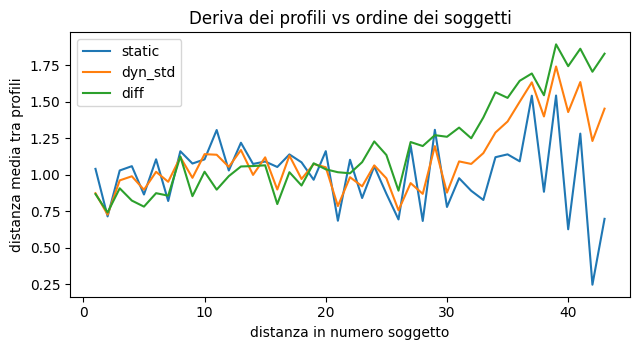

In [6]:
def subj_number(s):
    m = re.search(r'(\d+)$', s); return int(m.group(1)) if m else None

subs = sorted(set(rec_sid), key=natural_key)
nums_raw = [subj_number(s) for s in subs]
HAS_NUMS = all(n is not None for n in nums_raw)
if not HAS_NUMS:
    print('Nomi soggetto senza numero finale: salto il controllo di deriva.')
else:
    order = np.argsort(nums_raw); subs = [subs[i] for i in order]; nums = np.array([nums_raw[i] for i in order])
    num_of = dict(zip(subs, nums)); n_sub = len(subs)
    lag = np.abs(nums[:, None] - nums[None, :]); iu = np.triu_indices(n_sub, 1)
    rl = rankdata(lag[iu]); rl = rl - rl.mean()
    B = CFG['drift_perms']; prng = np.random.RandomState(CFG['seed'])
    perms = [np.arange(n_sub)] + [prng.permutation(n_sub) for _ in range(B)]
    big = np.eye(n_sub) * 1e9

    def drift_stats(D):
        rho, nn = [], []
        for p in perms:
            Dp = D[np.ix_(p, p)]
            rd = rankdata(Dp[iu]); rd = rd - rd.mean()
            rho.append((rl * rd).sum() / np.sqrt((rl ** 2).sum() * (rd ** 2).sum()))
            nn.append(lag[np.arange(n_sub), np.argmin(Dp + big, axis=1)].mean())
        rho, nn = np.array(rho), np.array(nn)
        return rho[0], (1 + (rho[1:] >= rho[0]).sum()) / (1 + B), nn[0], nn[1:].mean(), (1 + (nn[1:] <= nn[0]).sum()) / (1 + B)

    drift_rows, D_by_group = [], {}
    for g in GROUPS:
        Xg = feat_whole[g]; Zg = (Xg - Xg.mean(0)) / (Xg.std(0) + 1e-8)
        M = np.stack([Zg[rec_sid == s].mean(0) for s in subs]); M = l2(M - M.mean(0))
        D = 1 - M @ M.T; D_by_group[g] = D
        rho, p_rho, nn_obs, nn_null, p_nn = drift_stats(D)
        drift_rows.append({'gruppo': g, 'Spearman(lag, dist)': rho, 'p (deriva)': p_rho,
                           'vicino piu simile: |Δnum| osservato': nn_obs, 'atteso a caso': nn_null, 'p (vicini)': p_nn})
    drift = pd.DataFrame(drift_rows).set_index('gruppo').round(3)
    print(f'{n_sub} soggetti ordinati per numero; {B} permutazioni')
    display(drift)

    # distanza media dei profili statici per intervallo di lag
    bins = [1, 2, 4, 8, 16, 32, 100]
    lag_tab = []
    for g in ['static', 'dyn_std', 'diff']:
        D = D_by_group[g]
        lag_tab.append({'gruppo': g, **{f'lag {a}-{b - 1}': D[iu][(lag[iu] >= a) & (lag[iu] < b)].mean() for a, b in zip(bins[:-1], bins[1:])}})
    print('Distanza media fra profili per distanza in numero soggetto (se cresce con il lag: deriva):')
    display(pd.DataFrame(lag_tab).set_index('gruppo').round(3))

    # --- dove cadono i top-1 sbagliati? ---
    def wrong_top1(E, sid, act, protocol):
        G, Pm = act == GAL, act == PRB
        if protocol == 'cross': q_idx, g_idx, ex = np.where(Pm)[0], np.where(G)[0], False
        else:                   q_idx, g_idx, ex = np.where(G)[0], np.where(G)[0], True
        sim = E[q_idx] @ E[g_idx].T
        if ex: sim[np.arange(len(q_idx)), np.arange(len(q_idx))] = -np.inf
        top = g_idx[np.argmax(sim, axis=1)]
        ids_here = sorted(set(sid[q_idx]), key=natural_key); obs, exp = [], []
        for qi, ti in zip(q_idx, top):
            if sid[qi] != sid[ti]:
                obs.append(abs(num_of[sid[qi]] - num_of[sid[ti]]))
                exp.append(np.mean([abs(num_of[sid[qi]] - num_of[s]) for s in ids_here if s != sid[qi]]))
        return obs, exp

    loc_rows = []; brng = np.random.RandomState(0)
    for fs, rd in [('static', 'LDA'), ('basic', 'LDA')]:
        for protocol in ['cross', f'same_{GAL}']:
            obs, exp = [], []
            for tr, te in folds:
                E = embed_config(XS[fs], tr, REDUCERS[rd])[te]
                o, e = wrong_top1(E, rec_sid[te], rec_act[te], protocol); obs += o; exp += e
            d = np.array(obs) - np.array(exp)
            boot = [brng.choice(d, len(d)).mean() for _ in range(2000)]
            loc_rows.append({'metodo': f'{fs}+{rd}', 'protocollo': protocol, 'top-1 sbagliati': len(d),
                             '|Δnum| osservato': np.mean(obs), 'atteso a caso': np.mean(exp),
                             'differenza': d.mean(), 'IC95 differenza': f'[{np.percentile(boot, 2.5):.1f}, {np.percentile(boot, 97.5):.1f}]'})
    print('\nTop-1 SBAGLIATI: |Δ numero soggetto| fra query e identità restituita (differenza < 0 e IC95 che esclude 0 = errori fra soggetti vicini):')
    display(pd.DataFrame(loc_rows).set_index(['metodo', 'protocollo']).round(2))

    fig, ax = plt.subplots(figsize=(6.5, 3.6))
    for g in ['static', 'dyn_std', 'diff']:
        D = D_by_group[g]; lags = np.arange(1, n_sub)
        ax.plot(lags, [D[iu][lag[iu] == l].mean() if (lag[iu] == l).any() else np.nan for l in lags], label=g)
    ax.set_xlabel('distanza in numero soggetto'); ax.set_ylabel('distanza media tra profili'); ax.legend(); ax.set_title('Deriva dei profili vs ordine dei soggetti')
    plt.tight_layout(); plt.show()

## 7. Rete neurale (stesso modello di v7) — usata solo se `curve_neural=True`

In [7]:
def sliding_windows(arr, n, stride):
    return [arr[s:s + n] for s in range(0, arr.shape[0] - n + 1, stride)]

def band_edges(n, k):
    src, dst = [], []
    for i in range(n):
        for j in range(max(0, i - k), min(n, i + k + 1)):
            if i != j: src.append(i); dst.append(j)
    return torch.tensor([src, dst], dtype=torch.long)

class WiFiGAT(nn.Module):
    def __init__(self, cfg, n_classes):
        super().__init__()
        N, T = cfg['n_subcarriers'], cfg['n_packets']
        self.N, self.T, self.norm_mode = N, T, cfg['norm_mode']
        self.pos_emb = nn.Embedding(N, 16)
        def block(cin, cout, k):
            return nn.Sequential(nn.Conv1d(cin, cout, k, padding=k // 2), nn.BatchNorm1d(cout), nn.ReLU(), nn.MaxPool1d(2))
        self.temporal = nn.Sequential(block(1, 16, 5), block(16, 32, 5), block(32, 64, 3))
        self.temporal_fc = nn.Sequential(nn.Flatten(), nn.Dropout(cfg['dropout']), nn.Linear(64 * (T // 8), cfg['temporal_dim']), nn.ReLU())
        self.fusion = nn.Sequential(nn.Linear(cfg['temporal_dim'] + 16, cfg['temporal_dim']), nn.ReLU())
        self.register_buffer('base_edges', band_edges(N, cfg['band_k']))
        self.conv1 = GATConv(cfg['temporal_dim'], cfg['hidden'], heads=cfg['heads'], dropout=0.1)
        self.conv2 = GATConv(cfg['hidden'] * cfg['heads'], cfg['gat_out'], heads=1, concat=False, dropout=0.1)
        self.skip = nn.Linear(cfg['temporal_dim'], cfg['gat_out'])
        self.node_norm = nn.LayerNorm(cfg['gat_out'])
        self.head = nn.Sequential(nn.Dropout(cfg['dropout']), nn.Linear(2 * cfg['gat_out'], cfg['emb_dim']))
        self.bnneck = nn.BatchNorm1d(cfg['emb_dim'])
        self.classifier = nn.Linear(cfg['emb_dim'], n_classes, bias=False)

    def forward(self, x, batch):
        B = x.size(0) // self.N
        if self.norm_mode in ('scale', 'graph'):
            xg = x.view(B, self.N, self.T)
            if self.norm_mode == 'scale':
                xg = xg / (xg.mean(dim=(1, 2), keepdim=True) + 1e-5)
            else:
                xg = xg - xg.mean(dim=-1, keepdim=True); xg = xg / (xg.flatten(1).std(dim=1).view(B, 1, 1) + 1e-5)
            x = xg.reshape(B * self.N, self.T)
        off = (torch.arange(B, device=x.device) * self.N).view(1, B, 1)
        edge_index = (self.base_edges.unsqueeze(1) + off).reshape(2, -1)
        pos = self.pos_emb(torch.arange(x.size(0), device=x.device) % self.N)
        h0 = self.fusion(torch.cat([self.temporal_fc(self.temporal(x.unsqueeze(1))), pos], dim=1))
        h = F.elu(self.conv1(h0, edge_index))
        h, (_, alpha) = self.conv2(h, edge_index, return_attention_weights=True)
        h = self.node_norm(h + self.skip(h0))
        feat = self.head(torch.cat([global_mean_pool(h, batch), global_max_pool(h, batch)], dim=1))
        fb = self.bnneck(feat)
        return feat, fb, self.classifier(fb), alpha

def reid_loss(feat, logits, alpha, targets, cfg):
    emb = F.normalize(feat, dim=1)
    dist = (2.0 - 2.0 * emb @ emb.t()).clamp(min=1e-12).sqrt()
    same = targets.view(-1, 1) == targets.view(1, -1)
    d_ap = dist.masked_fill(~same, float('-inf')).max(dim=1).values
    d_an = dist.masked_fill(same, float('inf')).min(dim=1).values
    return (F.relu(d_ap - d_an + cfg['margin']).mean()
            + cfg['ce_weight'] * F.cross_entropy(logits, targets, label_smoothing=cfg['label_smoothing'])
            + cfg['lambda_gc'] * torch.mean(alpha ** 2))

def augment_batch(x, B, N, T, gain=(0.8, 1.25), noise=0.05, max_shift=10, node_drop=0.10):
    x = x.view(B, N, T); dev = x.device
    x = x * torch.empty(B, 1, 1, device=dev).uniform_(*gain)
    x = x + noise * x.std(dim=(1, 2), keepdim=True) * torch.randn_like(x)
    sh = torch.randint(-max_shift, max_shift + 1, (B,)).tolist()
    x = torch.stack([torch.roll(x[b], sh[b], dims=-1) for b in range(B)])
    mask = (torch.rand(B, N, 1, device=dev) < node_drop)
    return torch.where(mask, x.mean(dim=-1, keepdim=True).expand_as(x), x).reshape(B * N, T)

class PKRecSampler:
    def __init__(self, labels, recs_of_win, P, K, n_batches):
        self.tree = defaultdict(lambda: defaultdict(list))
        for i, (y, r) in enumerate(zip(labels, recs_of_win)): self.tree[y][r].append(i)
        self.classes = list(self.tree); self.P = min(P, len(self.classes)); self.K = K; self.n = n_batches
    def __len__(self): return self.n
    def __iter__(self):
        for _ in range(self.n):
            batch = []
            for c in random.sample(self.classes, self.P):
                rs = list(self.tree[c]); ch = random.sample(rs, self.K) if len(rs) >= self.K else random.choices(rs, k=self.K)
                batch.extend(random.choice(self.tree[c][r]) for r in ch)
            yield batch

win_x, win_rec = [], []
for ri, r in enumerate(recs):
    for w in sliding_windows(r['data'], CFG['n_packets'], CFG['stride']):
        win_x.append(torch.tensor(w.T.copy(), dtype=torch.float32)); win_rec.append(ri)
win_rec = np.array(win_rec)

@torch.no_grad()
def embed_windows(model, idx, bs=128):
    model.eval(); out = []
    for i in range(0, len(idx), bs):
        sel = idx[i:i + bs]
        x = torch.cat([win_x[j] for j in sel]).to(device)
        b = torch.arange(len(sel)).repeat_interleave(CFG['n_subcarriers']).to(device)
        out.append(F.normalize(model(x, b)[1], dim=1).cpu())
    return torch.cat(out).numpy()

def rec_embeddings(model, test_rec_idx):
    widx = np.where(np.isin(win_rec, test_rec_idx))[0]
    Fw = embed_windows(model, widx)
    return l2(np.stack([Fw[win_rec[widx] == r].mean(0) for r in test_rec_idx]))

def train_fold(train_rec_idx, seed):
    set_seed(seed)
    ids = sorted(set(rec_sid[train_rec_idx])); lab = {s: i for i, s in enumerate(ids)}
    widx = np.where(np.isin(win_rec, train_rec_idx))[0]
    labels = [lab[rec_sid[win_rec[j]]] for j in widx]
    model = WiFiGAT(CFG, len(ids)).to(device)
    opt = optim.AdamW(model.parameters(), lr=CFG['lr'], weight_decay=CFG['weight_decay'])
    sched = optim.lr_scheduler.CosineAnnealingLR(opt, T_max=CFG['n_epochs'])
    sampler = PKRecSampler(labels, [win_rec[j] for j in widx], CFG['P'], CFG['K'], CFG['batches_per_epoch'])
    for epoch in range(CFG['n_epochs']):
        model.train()
        for idx in sampler:
            sel = [widx[i] for i in idx]
            x = torch.cat([win_x[j] for j in sel]).to(device)
            if CFG['augment']: x = augment_batch(x, len(sel), CFG['n_subcarriers'], CFG['n_packets'])
            b = torch.arange(len(sel)).repeat_interleave(CFG['n_subcarriers']).to(device)
            y = torch.tensor([lab[rec_sid[win_rec[j]]] for j in sel], device=device)
            feat, _, logits, alpha = model(x, b)
            loss = reid_loss(feat, logits, alpha, y, CFG)
            opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), CFG['grad_clip']); opt.step()
        sched.step()
    return model
print(f'{len(win_x)} finestre pronte (rete usata solo se curve_neural=True)')

1515 finestre pronte (rete usata solo se curve_neural=True)


## 8. Curva di apprendimento: stesso test, sempre meno identità di training

curva (handcrafted) in 14.8s
Chance mAP media4: 14.4


mAP media4                   cross mAP                   same mAP                  
n_train                         8     16    24    33        8     16    24    33       8     16    24    33
metodo                                                                                                     
basic | LDA                   29.5  31.9  32.3  32.7      26.2  28.0  27.6  28.2     33.3  36.4  37.3  37.6
basic | cos                   28.2  28.1  28.0  28.0      25.3  25.0  24.9  24.9     31.5  31.5  31.5  31.4
static | LDA                  33.3  34.0  34.3  34.3      29.6  29.4  29.7  30.0     37.8  39.2  39.5  39.2
static+diff | PCA20+LDA       28.6  30.0  29.8  30.0      25.8  26.7  26.6  27.3     32.0  33.7  33.4  33.3

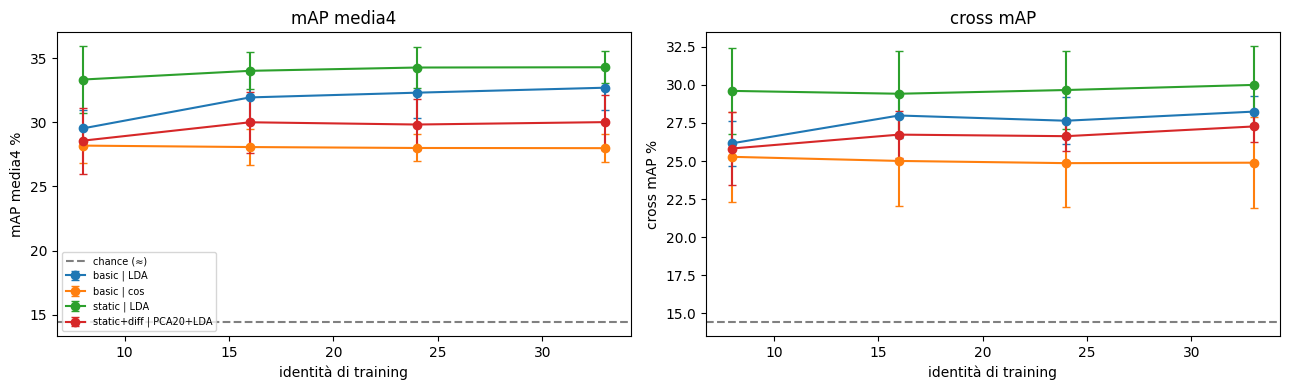

In [8]:
for fs, rd in CFG['curve_methods']:
    assert fs in FEATURE_SETS and rd in REDUCERS, f'curve_methods: {fs}/{rd} non valido'

max_train = len(set(rec_sid[folds[0][0]]))
sizes = [s for s in CFG['curve_sizes'] if s <= max_train]
if sizes != list(CFG['curve_sizes']):
    print(f'Dimensioni oltre {max_train} identità di training ignorate: uso {sizes}')

curve_rows = []
t0 = time.time()
for f, (tr, te) in enumerate(folds):
    tr_ids = sorted(set(rec_sid[tr]), key=natural_key)
    chance4 = None
    for n_tr in sizes:
        for rep in range(CFG['curve_repeats']):
            r_ = np.random.RandomState(CFG['seed'] * 1000 + f * 100 + n_tr * 7 + rep)
            sub = [tr_ids[i] for i in r_.permutation(len(tr_ids))[:n_tr]]
            sub_idx = tr[np.isin(rec_sid[tr], sub)]
            for fs, rd in CFG['curve_methods']:
                res = eval_cfg(XS[fs], REDUCERS[rd], sub_idx, te)
                curve_rows.append({'metodo': f'{fs} | {rd}', 'n_train': n_tr, 'fold': f, 'rep': rep,
                                   'mAP media4': mean_map(res), 'cross mAP': res['cross']['mAP'],
                                   'same mAP': np.mean([res[f'same_{GAL}']['mAP'], res[f'same_{PRB}']['mAP']]),
                                   'chance media4': np.mean([res[k]['chance_mAP'] for k in PROTOCOLS])})
print(f'curva (handcrafted) in {time.time() - t0:.1f}s')

if CFG['curve_neural']:
    for f, (tr, te) in enumerate(folds):
        tr_ids = sorted(set(rec_sid[tr]), key=natural_key)
        for n_tr in sizes:
            for rep in range(CFG['curve_neural_repeats']):
                r_ = np.random.RandomState(CFG['seed'] * 1000 + f * 100 + n_tr * 7 + rep)
                sub = [tr_ids[i] for i in r_.permutation(len(tr_ids))[:n_tr]]
                sub_idx = tr[np.isin(rec_sid[tr], sub)]
                model = train_fold(sub_idx, CFG['seed'] + f * 10 + rep)
                res = eval_protocols(rec_embeddings(model, te), rec_sid[te], rec_act[te])
                curve_rows.append({'metodo': 'rete neurale', 'n_train': n_tr, 'fold': f, 'rep': rep,
                                   'mAP media4': mean_map(res), 'cross mAP': res['cross']['mAP'],
                                   'same mAP': np.mean([res[f'same_{GAL}']['mAP'], res[f'same_{PRB}']['mAP']]),
                                   'chance media4': np.mean([res[k]['chance_mAP'] for k in PROTOCOLS])})
                print(f'  rete: fold {f + 1} n_train={n_tr} rep={rep}: mAP media4 {curve_rows[-1]["mAP media4"]:.1f}')

curve = pd.DataFrame(curve_rows)
summary = curve.groupby(['metodo', 'n_train'])[['mAP media4', 'cross mAP', 'same mAP']].mean().round(1)
print(f"Chance mAP media4: {curve['chance media4'].mean():.1f}")
display(summary.unstack('n_train'))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for j, col in enumerate(['mAP media4', 'cross mAP']):
    for name, g in curve.groupby('metodo'):
        s = g.groupby('n_train')[col].agg(['mean', 'std'])
        ax[j].errorbar(s.index, s['mean'], yerr=s['std'].fillna(0), marker='o', capsize=3, label=name)
    ax[j].axhline(curve['chance media4'].mean() if col == 'mAP media4' else curve.groupby('n_train')['chance media4'].mean().mean(),
                  color='gray', ls='--', label='chance (≈)')
    ax[j].set_xlabel('identità di training'); ax[j].set_ylabel(col + ' %'); ax[j].set_title(col)
ax[0].legend(fontsize=7)
plt.tight_layout(); plt.show()

## 9. Tabella finale (protocolli × metodo, media sui fold esterni)

In [9]:
def results_table(store):
    rows = []
    ch = aggregate_folds(next(iter(store.values())))
    rows.append({'metodo': 'CHANCE', **{f'{k} {m}': ch[(k, key)] for k in PROTOCOLS for m, key in [('R1', 'chance_rank1'), ('mAP', 'chance_mAP')]}})
    for name, res in store.items():
        a = aggregate_folds(res)
        rows.append({'metodo': name, **{f'{k} {m}': a[(k, key)] for k in PROTOCOLS for m, key in [('R1', 'rank1'), ('mAP', 'mAP')]}})
    return pd.DataFrame(rows).set_index('metodo').round(1)

print('=== RISULTATI (Rank-1 % / mAP %) ===')
display(results_table(store))
print('"Selezione ANNIDATA" è il numero da riportare: la configurazione è scelta solo con le identità di training di ogni fold.')

=== RISULTATI (Rank-1 % / mAP %) ===


,cross R1,cross mAP,cross_rev R1,cross_rev mAP,same_saluto R1,same_saluto mAP,same_tpose R1,same_tpose mAP
metodo,,,,,,,,
CHANCE,9.1,15.1,9.1,15.1,7.4,13.7,7.4,13.7
v7 rif.: basic + LDA,29.1,28.2,25.5,27.2,49.1,42.0,37.7,33.3
v7 rif.: all + LDA,22.3,25.3,19.1,24.6,36.4,33.7,25.0,27.9
static + LDA,30.0,30.0,26.4,28.6,48.6,41.6,40.0,36.9
Miglior config fissa [static | LDA] (ottimistica),30.0,30.0,26.4,28.6,48.6,41.6,40.0,36.9
Selezione ANNIDATA (onesta),30.0,30.0,26.4,28.6,48.6,41.6,40.0,36.9


"Selezione ANNIDATA" è il numero da riportare: la configurazione è scelta solo con le identità di training di ogni fold.


## 10. Come leggere i risultati

* **§5:** se la riga *Selezione ANNIDATA* ≈ *static + LDA* o ≈ *v7 rif.: basic + LDA*, la riduzione di dimensionalità non aggiunge nulla e il collo di bottiglia è il segnale. Se è chiaramente sopra, usa quella configurazione. Confrontala sempre con la riga ottimistica: la differenza misura quanto la selezione sul test gonfierebbe i risultati.
* **§6:** `p (deriva)` piccolo con `static` ma non con `dyn_std`/`diff` => il profilo statico contiene un fattore legato al tempo di acquisizione (sessione), e parte dell'accuratezza di `static` non è identità. Errori che cadono fra soggetti con numero vicino rafforzano questa lettura. Nessun effetto => la numerazione non mostra deriva (non esclude altre confusioni di sessione).
* **§8:** curva ancora in salita a 33 identità => più identità aiuterebbero e il limite è la quantità di dati; curva piatta => il limite è l'informazione nel segnale (ampiezza sola). Una curva che sale per la rete ma non per LDA indica che la rete è più affamata di dati.
* Fold std e 220 query per protocollo: differenze di 2–3 punti non sono significative.